# 02 · Training

This notebook trains two keypoint models on a validation split made **by person** and compares them on that split only:

- **v1:** the submitted architecture, retrained with correctly scaled inputs.
- **v2:** a compact head with BatchNorm, data augmentation and Wing loss.

The better one goes on to the final evaluation in [`03_evaluation`](03_evaluation.ipynb). The submitted model, **v0**, is kept as a reference.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable

import config

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

import metrics
import train
from data_load import FacialKeypointsDataset, identity_of
from models import load_trained

# Training both models takes ~25 min on an Apple M3 Pro. With RUN_TRAINING = False the
# notebook reads the saved logs (logs/) and checkpoints (models/) instead.
RUN_TRAINING = False
print("device:", config.DEVICE)

device: mps


## Starting point: the submitted model (v0)

| | v0 (Nanodegree submission) |
|---|---|
| Architecture | 3 conv blocks (32/64/128 channels, kernels 5/3/3) + ReLU + max-pool, dropout 0.3, FC 86,528 → 512 → 136 |
| Loss / optimizer | MSE on normalized keypoints, Adam (lr 5e-4) |
| Batch / epochs | 10 / 10 |
| Data | All 3,462 training images, no validation split |

The v0 training log, recovered from the output of the original notebook, already shows the problem. The loss reaches ~0.19 in the first epoch and stays there. That value is exactly the MSE of always predicting the average face under the same crops:

MSE of the best constant prediction: 0.190


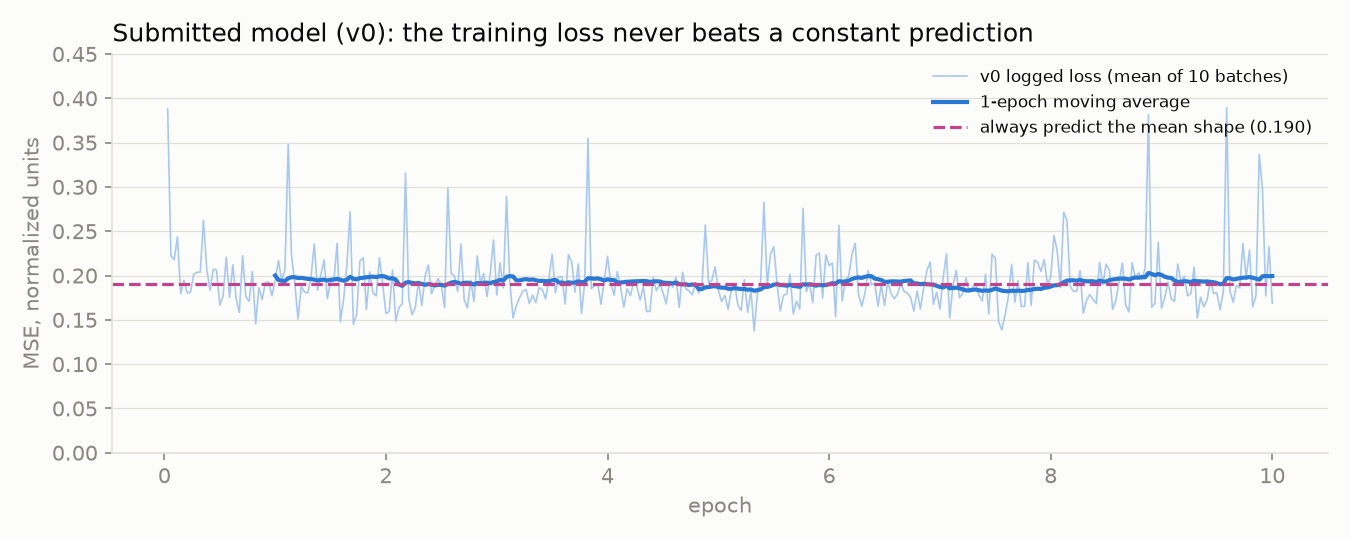

In [2]:
import importlib.util
spec = importlib.util.spec_from_file_location("plot_loss", config.PROJECT_ROOT / "scripts" / "plot_loss.py")
plot_loss = importlib.util.module_from_spec(spec)
spec.loader.exec_module(plot_loss)

constant_mse = plot_loss.mean_shape_mse()
print(f"MSE of the best constant prediction: {constant_mse:.3f}")
display(Image(filename=str(plot_loss.plot_v0_plateau(constant_mse))))

The cause is the double normalization described in notebook 01. The starter code read the PNG files with `matplotlib.image.imread`, which since matplotlib 3.3 returns them as floats in [0, 1], and `Normalize` then divided by 255 again. v0 therefore saw images in [0, 0.004]. The network found it easier to ignore the input and output the mean shape. Notebook 03 confirms this on the saved weights and explains how the bug was found.

`data_load.read_rgb` now reads images as `uint8`, and every model below is trained on correctly scaled [0, 1] inputs.

## Validation split by person

The official test set shares people and even video clips with the training set (notebook 01), so it cannot tell whether the model generalizes to new faces. The training CSV is therefore split **by person** with a fixed seed:

| Split | Share of people | Used for |
|---|---|---|
| train | 70 % | fitting the weights |
| validation | 15 % | LR schedule, early stopping, checkpoint selection, choosing between v1 and v2 |
| holdout | 15 % | final evaluation only (notebook 03). Not loaded in this notebook. |

In [3]:
train_df, val_df = train.load_splits()
people = {name: set(df.iloc[:, 0].map(identity_of)) for name, df in [("train", train_df), ("val", val_df)]}
assert not people["train"] & people["val"]
for name, df in [("train", train_df), ("val", val_df)]:
    print(f"{name:5s}: {len(df):4d} images, {len(people[name])} people")

train: 2409 images, 243 people
val  :  528 images, 52 people


## Design decisions

### v1: same model, correct inputs

v1 keeps the v0 architecture and loss. The goal is to measure what the input fix alone is worth.

- **Loss: MSE.** Keypoint detection is posed as a regression on 136 coordinates, so a classification loss does not apply. MSE penalizes the squared distance to the true points, and it is what v0 used.
- **Optimizer: Adam, lr 5e-4.** Same as v0. Adam adapts the step size per parameter, which matters here because `fc1` holds 99.6 % of the weights and the conv layers very few.
- **Architecture.** Three conv/ReLU/max-pool blocks followed by dropout 0.3 and two fully connected layers. It is deliberately simple: the goal of the original project was a correct end-to-end pipeline. Its weak point is that `fc1` maps 128 × 26 × 26 = 86,528 features to 512 units, which is 44 M of the 44.5 M parameters.
- **Batch size and epochs.** v0 used batch 10 and 10 epochs, chosen by watching the training loss: first one epoch to check that the loss went down, then 10. v1 uses batch 32, which gives 272 instead of 177 images/s on an M3 Pro. It trains for up to 100 epochs, but the number is not fixed by hand:
  - `ReduceLROnPlateau` halves the learning rate when the validation loss has not improved for 5 epochs.
  - Training stops when the validation NME has not improved for 12 epochs.
  - The saved checkpoint is the epoch with the best validation NME.

  Both models get the same cap of 100 epochs. v1 was first trained with a 60-epoch cap, and its best epoch was 57. Since it might have been cut off while still improving, it was retrained with the 100-epoch cap. The rerun matched the first run exactly over the first 60 epochs (training is deterministic with a fixed seed), and early stopping ended it at epoch 69 without beating epoch 57. v1 had converged.

### v2: three changes on top of v1

1. **Compact head.** A fourth conv block (256 channels), BatchNorm after every conv and adaptive average pooling to 6×6. `fc1` now sees 9,216 features, which brings the model from 44.5 M to 5.2 M parameters and the weights file from 178 MB to ~21 MB.
2. **Augmentation.** A horizontal flip with landmark relabeling: after a flip, point 36 (left eye corner) becomes point 45, and so on (`config.FLIP_PERMUTATION`). Also a rotation of ±15° and a scale of 0.9–1.1, applied before the random crop.
3. **Wing loss** (Feng et al., 2018), with the paper's `w = 10`, `ε = 2`, computed in pixels of the 224×224 input. It is logarithmic for small errors, so the last few pixels still produce a useful gradient, where MSE's gradient vanishes.

The three changes are tested together, so the comparison shows whether the package helps, not which change contributes what.

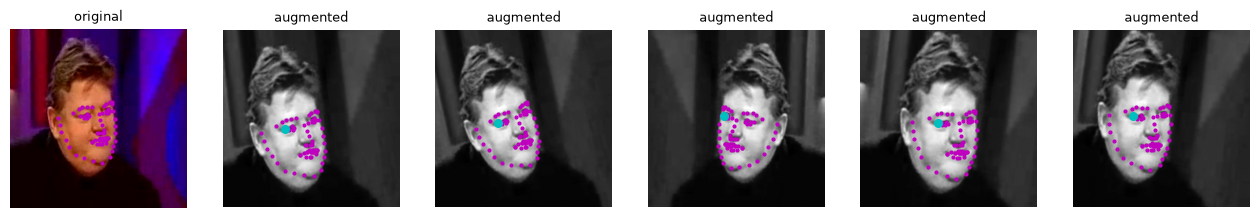

In [4]:
# What the v2 augmentation does to one training sample (several random draws)
np.random.seed(3)
raw = FacialKeypointsDataset(train_df, config.TRAIN_DIR)
aug = FacialKeypointsDataset(train_df, config.TRAIN_DIR, transform=train.train_transform(augment=True))
idx = 12
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
sample = raw[idx]
axes[0].imshow(sample["image"]); axes[0].scatter(*sample["keypoints"].T, s=4, c="m"); axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    s = aug[idx]
    pts = s["keypoints"].numpy() * config.KEYPOINT_STD + config.KEYPOINT_MEAN
    ax.imshow(s["image"][0], cmap="gray")
    ax.scatter(pts[:, 0], pts[:, 1], s=4, c="m")
    ax.scatter(*pts[config.LEFT_EYE_OUTER], s=30, c="c")   # point 36 should stay on the image-left eye
    ax.set_title("augmented", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

The cyan dot is point 36. After a flip it is still on the eye at the image's left, because the points are relabeled along with the mirroring.

## Training

In [5]:
logs = {}
for name in ("v1", "v2"):
    cfg = train.RUNS[name]
    if RUN_TRAINING:
        logs[name] = train.train(cfg)
    else:
        logs[name] = pd.read_csv(config.LOGS_DIR / f"training_log_{name}.csv")
    log = logs[name]
    best = log.loc[log.val_nme.idxmin()]
    print(f"{name}: {len(log)} epochs ({log.seconds.sum() / 60:.1f} min), best val NME "
          f"{100 * best.val_nme:.2f}% at epoch {int(best.epoch)}, final lr {log.lr.iloc[-1]:.1e}")

v1: 69 epochs (12.8 min), best val NME 13.88% at epoch 57, final lr 2.5e-04
v2: 97 epochs (18.5 min), best val NME 11.52% at epoch 85, final lr 7.8e-06


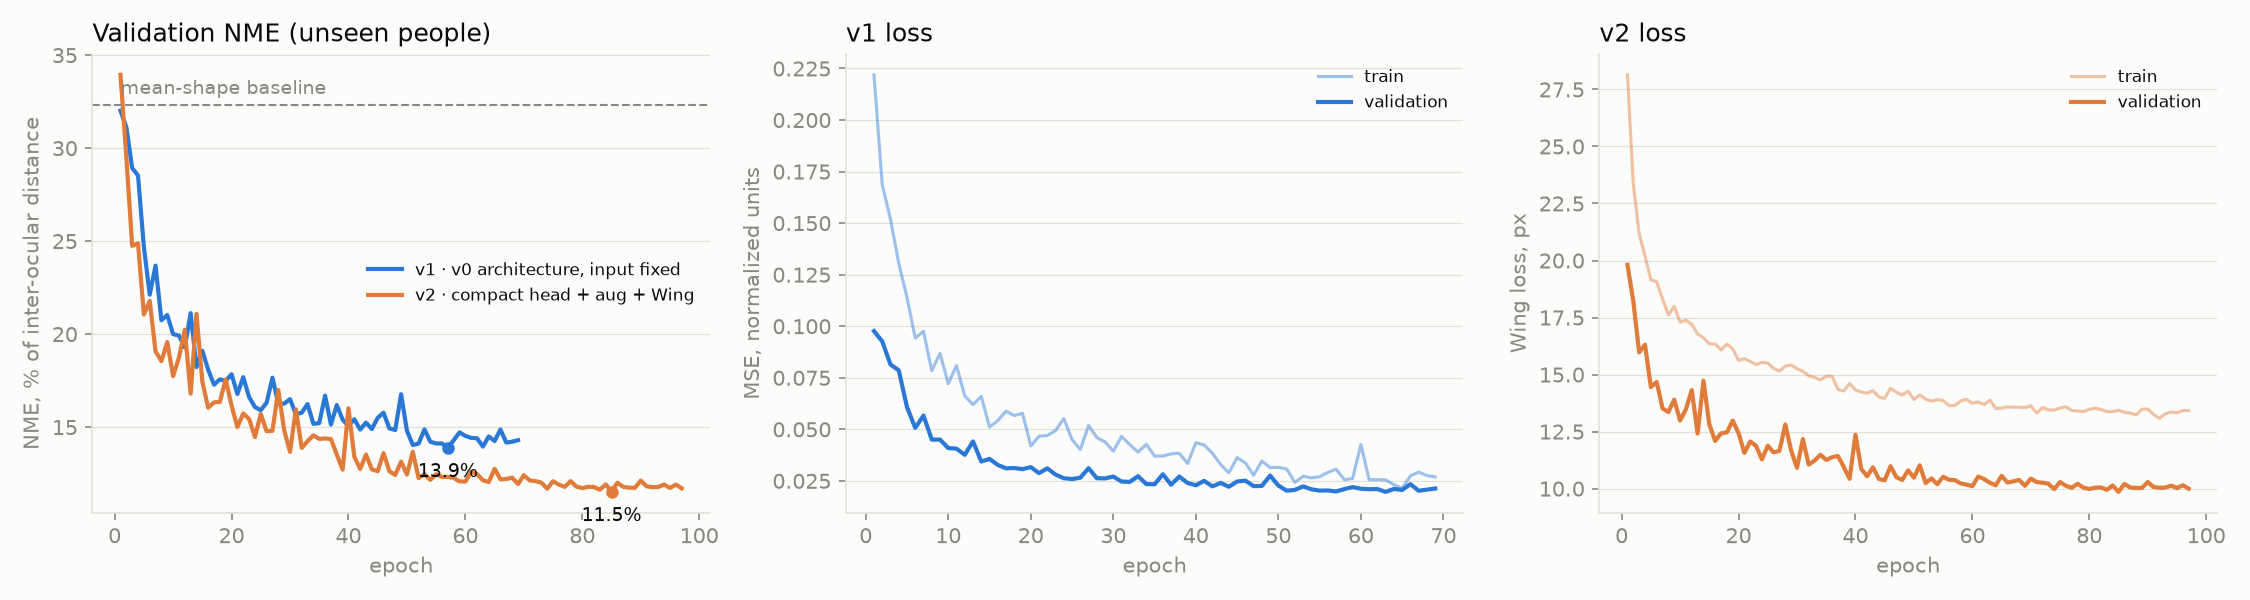

In [6]:
baseline_shape = metrics.fit_mean_shape(train_df, config.TRAIN_DIR)
gt_val = metrics.ground_truth(val_df)
baseline_val = metrics.predict_mean_shape(baseline_shape, val_df, config.TRAIN_DIR)
display(Image(filename=str(plot_loss.plot_curves(metrics.nme(baseline_val, gt_val).mean()))))

## Validation comparison

All numbers are on the 528 validation images (52 people unseen during training). Errors are measured in pixels of the **original** images. NME is the mean point error divided by the distance between the outer eye corners (points 36 and 45).

v0 is included for reference only. It was trained on all 347 people, so these validation faces are not new to it. Even so, it should match the baseline.

In [7]:
models = {"v0 (submitted)": config.V0_WEIGHTS, "v1": config.V1_WEIGHTS, "v2": config.V2_WEIGHTS}
preds = {"mean-shape baseline": baseline_val}
for name, path in models.items():
    preds[name] = metrics.predict_frame(load_trained(path), val_df, config.TRAIN_DIR)

table = pd.DataFrame({name: metrics.summary(p, gt_val) for name, p in preds.items()}).T
table.round(2)

,mean_px,median_px,nme_%,median_nme_%,failure_rate_%(nme>0.10)
mean-shape baseline,14.53,12.53,32.31,26.36,96.78
v0 (submitted),14.62,12.42,32.45,26.50,96.59
v1,6.30,5.36,13.92,11.36,60.42
v2,5.18,4.28,11.52,9.44,43.75


In [8]:
regions = pd.DataFrame({name: metrics.region_nme(p, gt_val) for name, p in preds.items()}).T
regions.round(1).rename(columns=lambda c: f"{c} NME %")

,jaw NME %,eyebrows NME %,nose NME %,eyes NME %,mouth NME %
mean-shape baseline,33.5,33.1,32.5,30.4,31.9
v0 (submitted),33.8,33.2,32.7,30.4,32.1
v1,15.9,14.5,12.8,12.2,13.4
v2,14.6,11.4,10.1,9.7,10.7


## Choosing the final model

**v2 is the better model on validation, and it is the one that goes to the final evaluation.**

- **v0 equals the baseline.** It scores 14.6 px against 14.5 px, in every facial region, even though it saw these people during training. That fits the diagnosis: the submitted model outputs a constant.
- **Fixing the inputs is by far the largest gain.** v1 has the same architecture, loss and optimizer as v0, yet its error drops from 14.6 px to 6.3 px (NME from 32 % to 14 %).
- **v2 improves on v1 everywhere.** Mean error goes from 6.3 to 5.2 px and NME from 13.9 % to 11.5 %. Every region improves, most of all the eyebrows, eyes and nose. v2 is better on 71 % of the validation images. A bootstrap over the 52 validation *people* puts the NME gain at 2.4 points (95 % CI 1.6–3.2), so it is not an artifact of a few faces. It also has 8.6× fewer parameters.
- **Remaining error.** The jaw is the hardest region for both models. Its 17 points lie along the face outline instead of on sharp features like the eye corners, so they are harder to pin down. Notebook 03 checks this against the failure cases. A large share of validation images is still above NME 0.10, which is a strict threshold for these small, low-resolution faces (the median inter-ocular distance is ~44 px).

Validation also chose the checkpoints and the learning-rate schedule, so these numbers are slightly optimistic. The unbiased estimate is the untouched holdout in notebook 03.


## Appendix: what the first conv layer learned

The 32 filters of `conv1` in the chosen model, and the response of a few of them to a validation face. This replaces the original feature-visualization exercise.

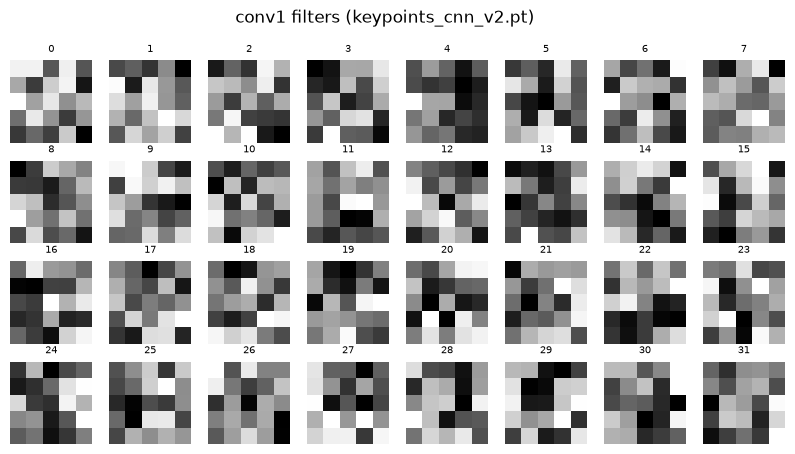

In [9]:
final = load_trained(config.FINAL_WEIGHTS)
first_conv = next(m for m in final.modules() if isinstance(m, torch.nn.Conv2d))
w = first_conv.weight.detach().cpu().numpy()[:, 0]

fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for k, ax in enumerate(axes.flat):
    ax.imshow(w[k], cmap="gray"); ax.set_title(str(k), fontsize=7); ax.axis("off")
fig.suptitle(f"conv1 filters ({config.FINAL_WEIGHTS.name})")
plt.show()

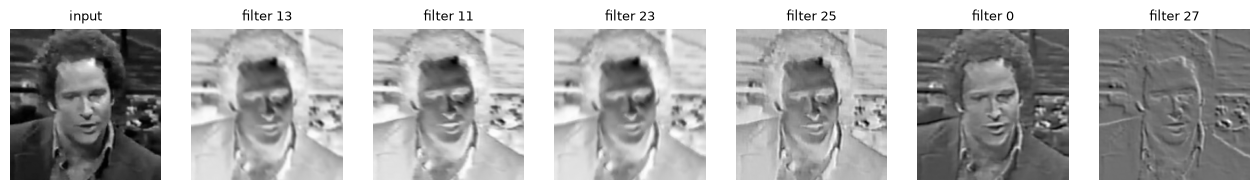

In [10]:
import torch.nn.functional as F

x = train.EVAL_TRANSFORM(FacialKeypointsDataset(val_df, config.TRAIN_DIR)[0])["image"][None]
with torch.no_grad():
    maps = F.conv2d(x, first_conv.weight.cpu()).numpy()[0]   # raw responses (no bias, BN or ReLU)

# Show the filters with the strongest and most varied responses
order = np.argsort(maps.reshape(len(maps), -1).std(axis=1))[::-1][:6]
fig, axes = plt.subplots(1, 7, figsize=(16, 2.8))
axes[0].imshow(x[0, 0], cmap="gray"); axes[0].set_title("input", fontsize=9)
for ax, k in zip(axes[1:], order):
    ax.imshow(maps[k], cmap="gray"); ax.set_title(f"filter {k}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

The filters are noisy 5×5 patterns rather than the clean, oriented edge detectors that textbook figures show. With BatchNorm right after it, `conv1` does not need tidy weights to be useful.

Their responses split into three groups:

- **Inverted intensity.** Filters 11, 13, 23 and 25, the strongest ones, act mostly as inverted-intensity detectors: the face comes out dark against a bright background, with eyes, nostrils and mouth as the darkest spots.
- **Pass-through.** Filter 0 lets a smoothed copy of the image through.
- **Edges.** Filter 27 gives an emboss-like edge map that traces the outline of the eyes, nose, mouth, hair and jaw.

The edges that the keypoints sit on are mostly put together in the deeper layers.